# Dữ liệu Titanic (train.csv)
**Nguồn trong đề:** Lab 2 — bài tập 2.1.3

Notebook độc lập cho một tập dữ liệu; code lấy từ các ô tương ứng của notebook Lab2 (giữ nguyên, ô nào chỉnh có ghi `# [Chỉnh]`).

In [1]:
# Thư viện dùng chung (đề import rải rác ở nhiều ô; gom lại để notebook chạy độc lập)
import os
if os.path.basename(os.getcwd()) == 'notebooks':   # chạy notebook từ thư mục notebooks/ thì lùi ra thư mục gốc chứa data/
    os.chdir('..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import matplotlib as mpl
import graphviz
from sklearn import tree, svm
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
titanic = pd.read_csv('data/train.csv')
print(titanic.shape)
print(titanic.isnull().sum()[lambda s: s>0])
# Tiền xử lý: điền tuổi thiếu bằng median, mã hóa giới tính và cảng lên tàu
t = titanic[['Survived','Pclass','Sex','Age','SibSp','Parch','Fare','Embarked']].copy()
t['Age'] = t['Age'].fillna(t['Age'].median())
t['Embarked'] = t['Embarked'].fillna(t['Embarked'].mode()[0])
t['Sex'] = t['Sex'].map({'male':0,'female':1})
t = pd.get_dummies(t, columns=['Embarked'], drop_first=True)
X = t.drop(columns='Survived'); y = t['Survived']
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=24, stratify=y)
t.head()

(891, 12)
Age         177
Cabin       687
Embarked      2
dtype: int64


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_Q,Embarked_S
0,0,3,0,22.0,1,0,7.2500,False,True
1,1,1,1,38.0,1,0,71.2833,False,False
2,1,3,1,26.0,0,0,7.9250,False,True
3,1,1,1,35.0,1,0,53.1000,False,True
4,0,3,0,35.0,0,0,8.0500,False,True


Cây quyết định - tham số tốt nhất: {'max_depth': 3}  AUC(CV) = 0.8561
Accuracy trên tập test: 0.8156


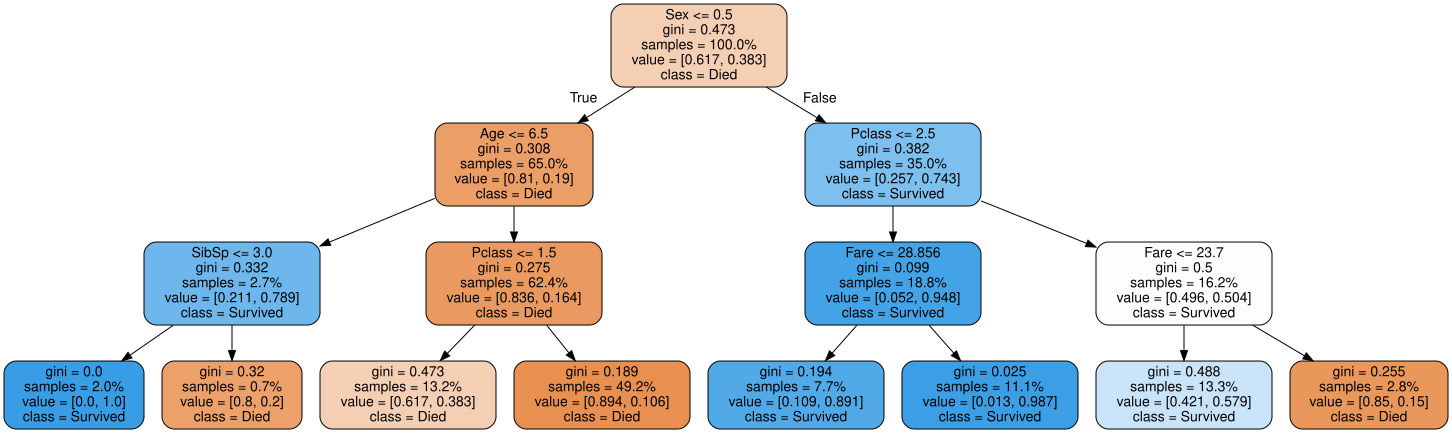

In [3]:
# Cây quyết định: chọn max_depth bằng GridSearchCV
gs = GridSearchCV(tree.DecisionTreeClassifier(random_state=24),
                  {'max_depth':[1,2,3,4,5,6,8,10]}, scoring='roc_auc', cv=4, return_train_score=True)
gs.fit(Xtr, ytr)
print("Cây quyết định - tham số tốt nhất:", gs.best_params_, " AUC(CV) = %.4f" % gs.best_score_)
best_dt = gs.best_estimator_
print("Accuracy trên tập test: %.4f" % accuracy_score(yte, best_dt.predict(Xte)))
dot = tree.export_graphviz(best_dt, out_file=None, filled=True, rounded=True, feature_names=list(X.columns),
                           proportion=True, class_names=['Died','Survived'])
graphviz.Source(dot).render('Reports/titanic_tree', format='png', cleanup=True)
graphviz.Source(dot)

Random Forest - tham số tốt nhất: {'n_estimators': 60}  AUC(CV) = 0.8615
Accuracy trên tập test: 0.8436
              precision    recall  f1-score   support

        Died       0.84      0.93      0.88       110
    Survived       0.86      0.71      0.78        69

    accuracy                           0.84       179
   macro avg       0.85      0.82      0.83       179
weighted avg       0.85      0.84      0.84       179



<Axes: title={'center': 'Feature importance - Titanic'}>

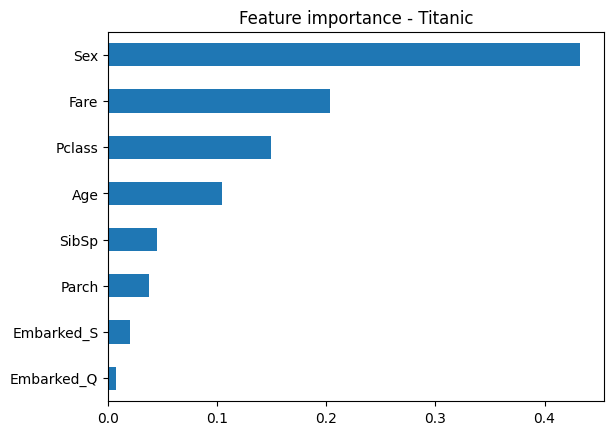

In [4]:
# Rừng cây
gs_rf = GridSearchCV(RandomForestClassifier(max_depth=5, random_state=4),
                     {'n_estimators':list(range(10,110,10))}, scoring='roc_auc', cv=4)
gs_rf.fit(Xtr, ytr)
print("Random Forest - tham số tốt nhất:", gs_rf.best_params_, " AUC(CV) = %.4f" % gs_rf.best_score_)
pred = gs_rf.best_estimator_.predict(Xte)
print("Accuracy trên tập test: %.4f" % accuracy_score(yte, pred))
print(classification_report(yte, pred, target_names=['Died','Survived']))
pd.Series(gs_rf.best_estimator_.feature_importances_, index=X.columns).sort_values().plot.barh(title='Feature importance - Titanic')